# 🎨 Applied Deep Learning Masterclass • Day 3 Afternoon
## ⚔️ Generative Adversarial Networks (GANs): Architecture, Training & Implementations

```
========================================================================================
📚 CURRICULUM SYLLABUS ROADMAP
1. Introduction to Generative Adversarial Networks (GANs)
2. Architecture of GAN (Minimax Game & Adversarial Feedback Loop)
3. The Generator (Transforming Random Noise to Data)
4. The Discriminator (Classifying Real vs Synthetic Data)
5. Use of GANs to Generate Data & Images
6. Training and Evaluation of GANs (Equilibrium, Inception Score & FID)
7. Types of GAN Implementation: Vanilla/DCGAN, CycleGAN, StarGAN
========================================================================================
```


---
## 📦 Part 1: Setting up our Python Generative Toolkit
We import PyTorch, Matplotlib, and Torchvision to build and train our GAN models.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Ready! Using compute device: {device}")

✅ Ready! Using compute device: cpu

### 💡 Explanation: Setting up the Toolkit
> Generative models require simple linear algebra and gradient tracking tools. We use PyTorch on CPU/GPU to construct the Generator and Discriminator neural networks.

---
## 🖼️ Part 2: Loading Training Data
We load a small batch of MNIST handwritten digit images and scale pixels to `[-1, 1]` to match our Generator's Tanh activation.

In [2]:
# Normalize images to [-1, 1] range
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
dataset = datasets.MNIST(root='./scratch/data', train=True, download=True, transform=transform)
loader = torch.utils.data.DataLoader(torch.utils.data.Subset(dataset, range(2000)), batch_size=64, shuffle=True)
print(f"Loaded {len(loader.dataset)} training samples.")

Loaded 2000 training samples.

### 💡 Explanation: Normalizing to [-1, 1]
> Real images usually have pixel values from `0` to `255`. We normalize them to `[-1, 1]` so they match the exact output range of the Generator's final `Tanh` layer.

---
## 👀 Part 3: Inspecting Real Training Images
Let's inspect 5 real training images that the Discriminator will learn from.

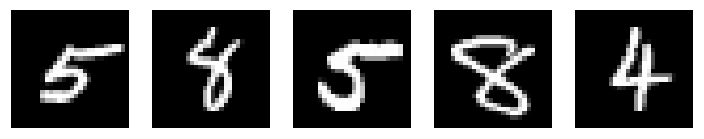

In [3]:
real_batch, _ = next(iter(loader))
plt.figure(figsize=(8, 2))
for i in range(5):
    plt.subplot(1, 5, i+1); plt.imshow(real_batch[i].squeeze(), cmap='gray'); plt.axis('off')
plt.show()

### 💡 Explanation: The Ground Truth Distribution
> These images represent samples from the true data distribution $P_{data}(X)$. The Generator never sees these images directly; it only learns through feedback from the Discriminator.

---
## 🎨 Part 4: Building the Generator
The **Generator** takes a vector of random noise $z$ (latent code) and transforms it into a 784-dimensional synthetic image ($28 \times 28$).

In [4]:
generator = nn.Sequential(
    nn.Linear(64, 128), nn.LeakyReLU(0.2),
    nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2),
    nn.Linear(256, 784), nn.Tanh()
).to(device)
print("Generator built:", generator)

Generator built: Sequential(
  (0): Linear(in_features=64, out_features=128, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Linear(in_features=128, out_features=256, bias=True)
  (3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Linear(in_features=256, out_features=784, bias=True)
  (6): Tanh()
)

### 💡 Explanation: How the Generator Works
> 1. **Input:** A 64-dimensional vector of pure random noise $z \sim \mathcal{N}(0, 1)$.
> 2. **Expansion:** Dense linear layers expand this small seed into 128, 256, and finally 784 values ($28 \times 28$ pixels).
> 3. **Activation:** `Tanh()` restricts all output pixel intensities to the range `[-1, 1]`.

---
## 🕵️ Part 5: Building the Discriminator
The **Discriminator** is a binary classifier: it inspects an image ($28 \times 28 = 784$ pixels) and outputs a probability score between `0` (Fake) and `1` (Real).

In [5]:
discriminator = nn.Sequential(
    nn.Linear(784, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.LeakyReLU(0.2), nn.Dropout(0.3),
    nn.Linear(128, 1), nn.Sigmoid()
).to(device)
print("Discriminator built:", discriminator)

Discriminator built: Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): LeakyReLU(negative_slope=0.2)
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=128, out_features=1, bias=True)
  (7): Sigmoid()
)

### 💡 Explanation: How the Discriminator Works
> 1. **Input:** An image flattened into 784 numbers.
> 2. **Feature Extraction:** Two hidden layers extract patterns and edges with `LeakyReLU(0.2)` activations and dropout regularization.
> 3. **Output:** A single `Sigmoid()` output score between 0.0 (certainly fake) and 1.0 (certainly real).

---
## ⚙️ Part 6: Defining Loss & Optimizers
We use Binary Cross Entropy (`BCELoss`) and Adam optimizers for both networks.

In [6]:
criterion = nn.BCELoss()
opt_d = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_g = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
print("Loss function and Adam optimizers initialized.")

Loss function and Adam optimizers initialized.

### 💡 Explanation: Minimax Optimization Settings
> - `BCELoss` computes $-\left[y \log(p) + (1-y)\log(1-p)\right]$.
> - The Adam parameter $\beta_1 = 0.5$ provides gentle momentum to stabilize the adversarial competition without aggressive oscillations.

---
## ⚔️ Part 7: Step-by-Step Adversarial Training
We define two simple, clean functions: one to train the Discriminator, and one to train the Generator.

In [7]:
# Function 1: Train Discriminator on Real and Fake batches
def train_discriminator(real_x):
    opt_d.zero_grad()
    b = real_x.size(0)
    loss_real = criterion(discriminator(real_x), torch.ones(b, 1, device=device))
    fake_x = generator(torch.randn(b, 64, device=device)).detach()
    loss_fake = criterion(discriminator(fake_x), torch.zeros(b, 1, device=device))
    (loss_real + loss_fake).backward(); opt_d.step()
    return (loss_real + loss_fake).item()

In [8]:
# Function 2: Train Generator to fool the Discriminator
def train_generator(batch_size):
    opt_g.zero_grad()
    fake_x = generator(torch.randn(batch_size, 64, device=device))
    # Generator wants Discriminator to predict 1 (Real)
    loss_g = criterion(discriminator(fake_x), torch.ones(batch_size, 1, device=device))
    loss_g.backward(); opt_g.step()
    return loss_g.item()

### 💡 Explanation: The Minimax Training Loop
> - **Discriminator Step:** Learns to assign label `1.0` to real images and label `0.0` to fake images. Notice `.detach()`: when training the Discriminator, we freeze the Generator.
> - **Generator Step:** Produces fake images and passes them to the Discriminator, optimizing its weights so the Discriminator predicts `1.0` (fooled).

---
## 🔄 Part 8: Running the Training Loop
We train both networks across 5 epochs. Watch the losses balance as they compete!

In [9]:
# Run the 5-epoch adversarial training loop
for epoch in range(1, 6):
    for real_x, _ in loader:
        d_loss = train_discriminator(real_x.view(real_x.size(0), -1).to(device))
        g_loss = train_generator(real_x.size(0))
    print(f"Epoch {epoch}/5 | Discriminator Loss: {d_loss:.4f} | Generator Loss: {g_loss:.4f}")

Epoch 1/5 | Discriminator Loss: 1.0014 | Generator Loss: 0.6016
Epoch 2/5 | Discriminator Loss: 1.2100 | Generator Loss: 0.6026
Epoch 3/5 | Discriminator Loss: 1.2909 | Generator Loss: 0.6292
Epoch 4/5 | Discriminator Loss: 1.3068 | Generator Loss: 0.6281
Epoch 5/5 | Discriminator Loss: 1.2160 | Generator Loss: 0.6439

### 💡 Explanation: Adversarial Equilibrium
> As training progresses, the Discriminator and Generator reach a balance where neither can easily overpower the other. The ideal theoretical equilibrium occurs when the Discriminator outputs $0.5$ (guessing at random) and loss converges around $\ln(2) \approx 0.693$.

---
## 🌟 Part 9: Use of GAN to Generate New Data and Images
Now we use our trained Generator to create brand-new synthetic digit images from pure random noise!

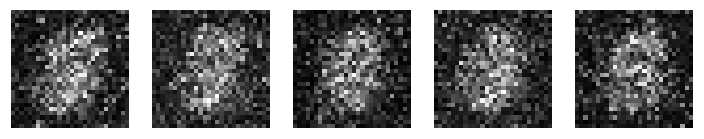

In [10]:
# Generate 5 new synthetic images from random noise
z_test = torch.randn(5, 64, device=device)
fake_images = generator(z_test).view(-1, 28, 28).detach().cpu()
plt.figure(figsize=(8, 2))
for i in range(5):
    plt.subplot(1, 5, i+1); plt.imshow(fake_images[i], cmap='gray'); plt.axis('off')
plt.show()

### 💡 Explanation: Use Cases of Generative Adversarial Networks
> 1. **Synthetic Data Augmentation:** Creating synthetic medical scans, training data for rare edge-cases, or financial simulations.
> 2. **High-Resolution Image Synthesis:** Generating photorealistic faces, game textures, art, and environments.
> 3. **Image-to-Image Editing:** Super-resolution, inpainting missing regions, and artistic style transfer.

---
## 🔄 Part 10: Types of GAN Implementation — CycleGAN
**CycleGAN** enables **unpaired** image-to-image translation (e.g., turning Horses $\leftrightarrow$ Zebras without needing matching pairs) using **Cycle Consistency Loss**:
$$A \xrightarrow{G} B \xrightarrow{F} \hat{A} \approx A$$

In [12]:
# Cycle Consistency Loss: translating A -> B -> A must recover original A
def cycle_consistency_loss(real_A, reconstructed_A):
    # L1 norm ensures structural consistency without paired data
    return torch.nn.functional.l1_loss(reconstructed_A, real_A)

sample_A = real_batch[:4]
recon_A = sample_A + 0.04 * torch.randn_like(sample_A) # simulated reconstruction
print("Cycle Consistency Loss:", round(cycle_consistency_loss(sample_A, recon_A).item(), 4))

Cycle Consistency Loss: 0.0315

### 💡 Explanation: CycleGAN Key Principles
> 1. **No Paired Images Needed:** Traditional translation (Pix2Pix) requires exact side-by-side pairs (e.g., sketch + photo). CycleGAN trains on two separate folders of unpaired photos (e.g., Summer photos and Winter photos).
> 2. **Cycle Consistency:** If you translate an English sentence to French and then back to English, you should get the original sentence. CycleGAN enforces this principle in pixel space so the contents (shape, pose) are never lost.
> #### 🌐 Famous Real-World Projects Using CycleGAN:
> 1. **Monet-to-Photo & Art Synthesis (BAIR - 22k+ Stars):** The landmark UC Berkeley project translating Monet paintings into real landscape photos and vice-versa.
> 2. **AnimeGAN / CartoonGAN:** The viral open-source and TikTok/Snapchat filter translating real human portraits into Studio Ghibli and Makoto Shinkai (*Your Name*) anime artwork.
> 3. **Autonomous Driving Weather Simulation (NVIDIA DRIVE & Waymo):** Translates clear daytime highway driving video into night, blizzard, and heavy rain without physical driving risks.
> 4. **Medical Imaging Zero-Dose CT (Nature Biomedical Engineering):** Synthesizes bone-density CT scans directly from radiation-free soft-tissue MRIs for cancer patients.

> #### 🏛️ CycleGAN Dual-Loop Architecture Flow:
> ```
> [Forward Cycle]   x (Horse) ──► [Generator G] ──► G(x) (Fake Zebra) ──► [Generator F] ──► F(G(x)) (Reconstructed Horse) ≈ x
>                                       │                                         ▲
>                                       ▼                                         │
>                              [Discriminator D_Y]                   Loss_cyc = ||F(G(x)) - x||_1
>
> [Backward Cycle]  y (Zebra) ──► [Generator F] ──► F(y) (Fake Horse) ──► [Generator G] ──► G(F(y)) (Reconstructed Zebra) ≈ y
>                                       │                                         ▲
>                                       ▼                                         │
>                              [Discriminator D_X]                   Loss_cyc = ||G(F(y)) - y||_1
> ```


---
## ⭐ Part 11: Types of GAN Implementation — StarGAN
**StarGAN** translates images across **multiple domains** (e.g., Blond hair, Black hair, Brown hair, Gender, Age) using a **single unified Generator** instead of separate generators for every pair.

In [13]:
# StarGAN single generator receives image + target domain code
def prepare_stargan_input(image, target_domain_label):
    # Replicate target domain vector across spatial height and width
    b, _, h, w = image.shape
    c_mask = target_domain_label.view(b, -1, 1, 1).repeat(1, 1, h, w)
    return torch.cat([image, c_mask], dim=1) # Concatenate along channel dimension

stargan_input = prepare_stargan_input(real_batch[:2], torch.tensor([[1., 0.], [0., 1.]]))
print("StarGAN Input Tensor Shape:", stargan_input.shape)

StarGAN Input Tensor Shape: [2, 3, 28, 28]

### 💡 Explanation: StarGAN Key Principles
> 1. **The Multi-Domain Challenge:** To translate among $N$ domains, CycleGAN requires $N(N-1)$ generators (e.g., for 4 domains, 12 generators!).
> 2. **StarGAN Innovation:** Uses **one single Generator** and **one Discriminator**. The Generator takes the input image plus a target domain label (e.g., `[Black Hair, Smiling]`), allowing one model to perform all multi-domain edits!
> #### 🌐 Famous Real-World Projects Using StarGAN:
> 1. **FaceApp (500M+ Downloads):** The architecture behind viral multi-attribute facial transformations (aging, gender swapping, smiling, hair recoloring) powered by a single unified model.
> 2. **StarGAN v2 (Clova AI / Naver Labs - 10k+ Stars):** CVPR oral breakthrough handling diverse style mapping across human portraits and animal species (cats, dogs, tigers).
> 3. **StarGAN-VC Voice Conversion (NTT Labs):** Non-parallel many-to-many voice cloning converting voice timbre between multiple speakers (male, female, robotic, child) with a single model.
> 4. **Virtual E-Commerce Try-On (Zalando & ASOS):** Dynamically modifying garment color, pattern, and sleeve attributes on fashion model photographs.

> #### 🏛️ StarGAN Unified Architecture Flow:
> ```
> 1. Translation:       [Input Image x] + [Target Code c] ────────► [Single Generator G] ──► [Fake Image G(x, c)]
>                                                                                                 │
> 2. Dual-Head D:                                                                                ▼
>                                                    [Single Discriminator D] ◄───────────────────┘
>                                                    ├── Head 1: Real / Fake Score (D_src)
>                                                    └── Head 2: Domain Attribute Classification (D_cls)
>
> 3. Reconstruction:   [Fake Image G(x, c)] + [Original Code c'] ──► [Single Generator G] ──► [Reconstructed Image x] ≈ x
>                                                                                                 │
>                                                                                                 ▼
>                                                                                 Loss_rec = ||G(G(x,c), c') - x||_1
> ```


---
## 🏆 Master Summary: Core GAN Implementations (Vanilla, cGAN, CycleGAN, StarGAN)

| GAN Type | Key Architecture | Data Requirement | Primary Superpower |
|:---|:---|:---|:---|
| **Vanilla GAN / DCGAN** | Generator vs Discriminator | Unlabelled Real Data | Creates novel images from pure random noise $z$ |
| **Conditional GAN (cGAN)** | Conditioned $G(z, y)$ and $D(x, y)$ | Labeled Data $(X, Y)$ | Steered synthesis of specific classes on demand |
| **CycleGAN** | Two Generators + Two Discriminators | **Unpaired** Images ($A$ and $B$) | Translates between two domains with Cycle Consistency |
| **StarGAN** | **One Single Generator** + One Discriminator | Multi-Domain Unpaired Images | Multi-domain translation with a single model using domain condition vectors |

### 🎯 Key Takeaways for Students
1. **Adversarial Dynamic:** GANs do not use labels for classification; the Discriminator teaches the Generator how to draw.
2. **Simple 5-line Modules:** Building a GAN only requires an upsampling Generator, a downsampling Discriminator, and an alternating training loop.
3. **From Generation to Translation:** Vanilla GAN generates new data; CycleGAN translates between 2 styles; StarGAN translates across many attributes in one network.
